# 07 · Storytelling Static Figures (Workshop 4, Part 3)

**Team 6 — Volcanic Activity Monitoring** · Data Analysis Programming 2026-II · Universidad Distrital

This notebook reads the latest `datalake_gold/storytelling_*.parquet` file and exports publication-ready **Seaborn** figures into `workshop_4/figures/` for the Workshop 4 technical report:
1. `story_tone_trajectory_distribution.png`: Weekly volcanic lexicon tone vs. VADER baseline and overall tone classification breakdown.
2. `story_top_keywords_by_tone.png`: Top 15 unigrams and bigrams colored by their mean volcanic activity tone.
3. `story_source_comparison_volume.png`: Bulletin length, activity tone, and weekly monitoring volume across USGS sources.

In [1]:
from pathlib import Path
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style='whitegrid', context='paper', font_scale=1.1)
TONE_PALETTE = {'escalating': '#D95F02', 'stable': '#8C8C8C', 'calming': '#1B9E77'}

repo_root = Path('..') if Path.cwd().name == 'notebooks' else Path('.')
gold_files = sorted((repo_root / 'datalake_gold').glob('storytelling_*.parquet'))
assert gold_files, 'No storytelling_*.parquet found in datalake_gold/'
latest_gold = gold_files[-1]
df = pd.read_parquet(latest_gold)

fig_dir = repo_root / 'workshop_4' / 'figures'
fig_dir.mkdir(parents=True, exist_ok=True)
print(f'Loaded {latest_gold.name} ({len(df):,} rows) | generated_utc={df["generated_utc"].iloc[0]}')

Loaded storytelling_20261128_032704.parquet (25,201 rows) | generated_utc=2026-11-28 03:27:04.013048


/tmp/ipykernel_46860/3638906786.py:33: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(['Escalating\n(> +0.15)', 'Stable\n(-0.15..+0.15)', 'Calming\n(< -0.15)'])


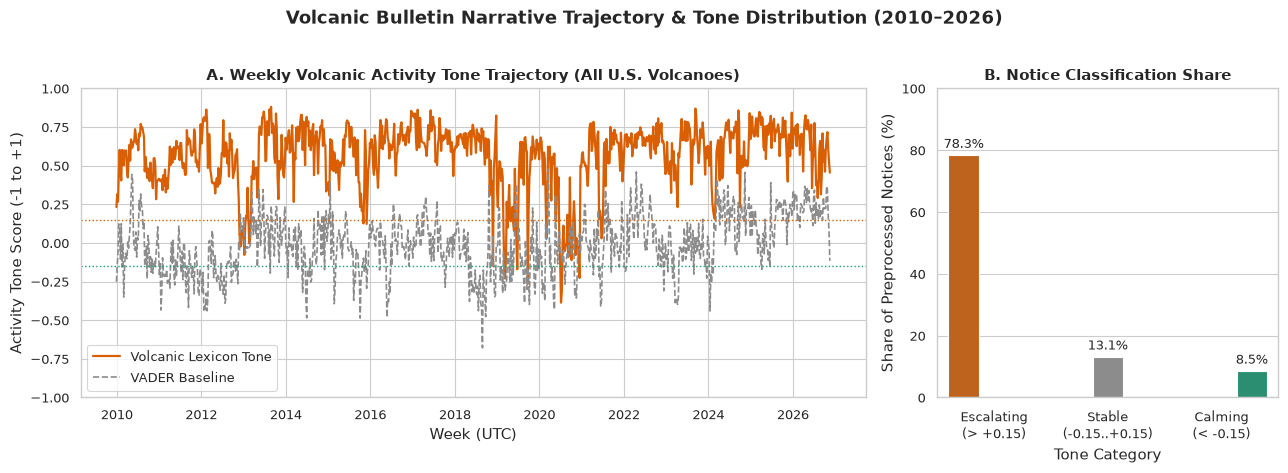

Saved: ../workshop_4/figures/story_tone_trajectory_distribution.png


In [2]:
# Figure 1: Weekly Activity Tone Trajectory & Overall Tone Distribution
tone = df[df['section'] == 'tone_weekly'].copy()
tone['period'] = pd.to_datetime(tone['period'])
lex = tone[(tone['metric'] == 'lexicon_mean') & (tone['dimension'] == 'ALL')].sort_values('period')
vad = tone[(tone['metric'] == 'vader_mean') & (tone['dimension'] == 'ALL')].sort_values('period')

dist = df[(df['section'] == 'tone_distribution') & (df['metric'] == 'pct_records')].copy()
order = ['escalating', 'stable', 'calming']
dist['dimension'] = pd.Categorical(dist['dimension'], categories=order, ordered=True)
dist = dist.sort_values('dimension')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [2.3, 1]})
sns.lineplot(data=lex, x='period', y='value', ax=ax1, color=TONE_PALETTE['escalating'], linewidth=1.6, label='Volcanic Lexicon Tone')
if not vad.empty:
    sns.lineplot(data=vad, x='period', y='value', ax=ax1, color=TONE_PALETTE['stable'], linewidth=1.2, linestyle='--', label='VADER Baseline')
ax1.axhline(0.15, color=TONE_PALETTE['escalating'], linestyle=':', linewidth=1)
ax1.axhline(-0.15, color=TONE_PALETTE['calming'], linestyle=':', linewidth=1)
ax1.set_ylim(-1, 1)
ax1.set_title('A. Weekly Volcanic Activity Tone Trajectory (All U.S. Volcanoes)', fontweight='bold')
ax1.set_xlabel('Week (UTC)')
ax1.set_ylabel('Activity Tone Score (-1 to +1)')
ax1.xaxis.set_major_locator(mdates.YearLocator(2))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax1.legend(loc='lower left', frameon=True)

sns.barplot(data=dist, x='dimension', y='value', hue='dimension', palette=TONE_PALETTE, legend=False, ax=ax2)
for container in ax2.containers:
    ax2.bar_label(container, fmt='%.1f%%', padding=3, fontsize=9.5)
ax2.set_ylim(0, 100)
ax2.set_title('B. Notice Classification Share', fontweight='bold')
ax2.set_xlabel('Tone Category')
ax2.set_ylabel('Share of Preprocessed Notices (%)')
ax2.set_xticklabels(['Escalating\n(> +0.15)', 'Stable\n(-0.15..+0.15)', 'Calming\n(< -0.15)'])

fig.suptitle('Volcanic Bulletin Narrative Trajectory & Tone Distribution (2010–2026)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
out1 = fig_dir / 'story_tone_trajectory_distribution.png'
fig.savefig(out1, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', out1)

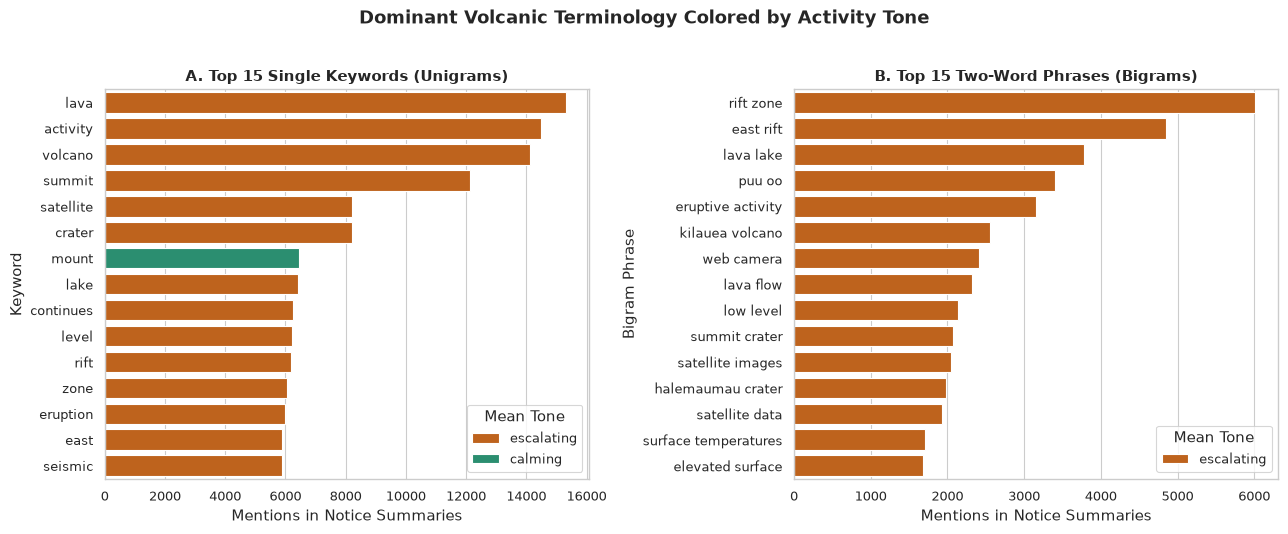

Saved: ../workshop_4/figures/story_top_keywords_by_tone.png


In [3]:
# Figure 2: Top 15 Keywords (Unigrams & Bigrams) Colored by Mean Activity Tone
kw = df[df['section'] == 'top_keywords'].copy()

def prep_ngrams(prefix):
    sub = kw[kw['dimension'].str.startswith(prefix)].copy()
    piv = sub.pivot(index='dimension', columns='metric', values='value').reset_index()
    piv['term'] = piv['dimension'].str.replace(prefix, '', regex=False)
    piv = piv.sort_values('frequency', ascending=False).head(15)
    piv['bucket'] = piv['mean_lexicon_tone'].apply(
        lambda v: 'escalating' if v > 0.15 else ('calming' if v < -0.15 else 'stable')
    )
    return piv

uni = prep_ngrams('unigram:')
bi = prep_ngrams('bigram:')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))
sns.barplot(data=uni, x='frequency', y='term', hue='bucket', palette=TONE_PALETTE, dodge=False, ax=ax1)
ax1.set_title('A. Top 15 Single Keywords (Unigrams)', fontweight='bold')
ax1.set_xlabel('Mentions in Notice Summaries')
ax1.set_ylabel('Keyword')
ax1.legend(title='Mean Tone', loc='lower right')

sns.barplot(data=bi, x='frequency', y='term', hue='bucket', palette=TONE_PALETTE, dodge=False, ax=ax2)
ax2.set_title('B. Top 15 Two-Word Phrases (Bigrams)', fontweight='bold')
ax2.set_xlabel('Mentions in Notice Summaries')
ax2.set_ylabel('Bigram Phrase')
ax2.legend(title='Mean Tone', loc='lower right')

fig.suptitle('Dominant Volcanic Terminology Colored by Activity Tone', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
out2 = fig_dir / 'story_top_keywords_by_tone.png'
fig.savefig(out2, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', out2)

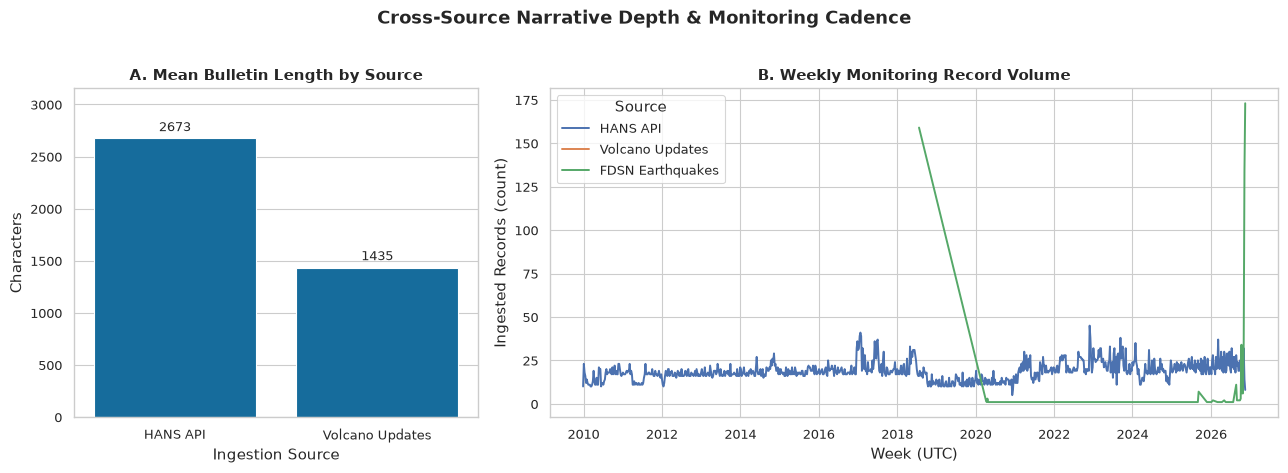

Saved: ../workshop_4/figures/story_source_comparison_volume.png


In [4]:
# Figure 3: Source Comparison (Mean Bulletin Length & Tone) + Weekly Record Volume
sc = df[df['section'] == 'source_comparison'].copy()
piv_sc = sc.pivot(index='dimension', columns='metric', values='value').reset_index()
label_map = {
    'usgs_hans_notices_api': 'HANS API',
    'usgs_volcano_updates_scraping': 'Volcano Updates',
    'usgs_earthquakes': 'FDSN Earthquakes',
}
piv_sc['Source'] = piv_sc['dimension'].map(label_map).fillna(piv_sc['dimension'])

vol = df[df['section'] == 'volume_activity'].copy()
vol['period'] = pd.to_datetime(vol['period'])
vol['Source'] = vol['dimension'].map(label_map).fillna(vol['dimension'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1, 1.8]})
sns.barplot(data=piv_sc, x='Source', y='mean_text_length', color='#0072B2', ax=ax1)
for container in ax1.containers:
    ax1.bar_label(container, fmt='%.0f', padding=3, fontsize=9.5)
ax1.set_ylim(0, piv_sc['mean_text_length'].max() * 1.18)
ax1.set_title('A. Mean Bulletin Length by Source', fontweight='bold')
ax1.set_xlabel('Ingestion Source')
ax1.set_ylabel('Characters')

sns.lineplot(data=vol, x='period', y='value', hue='Source', ax=ax2, linewidth=1.4)
ax2.set_title('B. Weekly Monitoring Record Volume', fontweight='bold')
ax2.set_xlabel('Week (UTC)')
ax2.set_ylabel('Ingested Records (count)')
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

fig.suptitle('Cross-Source Narrative Depth & Monitoring Cadence', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
out3 = fig_dir / 'story_source_comparison_volume.png'
fig.savefig(out3, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', out3)